# NHANES 2021–2023 — Bước 3: Exploratory Data Analysis (EDA)

**Dự án:** Multi-Agent AI System for Diabetes Risk Assessment  
**Người chạy:** Bạn, trong Jupyter Notebook trên máy cá nhân.  
**Trạng thái:** Các ô code trong file này **chưa được chạy**. **Không huấn luyện mô hình, không tạo nhãn cuối.**

## Mục tiêu
- Phân tích dữ liệu người ≥20 tuổi từ 4 file XPT của Bước 2.
- Đánh giá thiếu dữ liệu, overlap giữa `LBXGH` và `BMXBMI`, phân bố và quan hệ mô tả.
- Lưu biểu đồ PNG và gửi bảng tổng hợp cuối cho người hướng dẫn.

**Nguồn CDC**: [DEMO_L](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm) · [BMX_L](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/BMX_L.htm) · [GHB_L](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/GHB_L.htm) · [DIQ_L](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DIQ_L.htm)

> Quan trọng: Các thống kê/biểu đồ bên dưới là **mô tả chưa áp dụng thiết kế khảo sát** (unweighted). Không được xem là tỷ lệ đại diện dân số Hoa Kỳ hay nguy cơ mắc tiểu đường trong tương lai.

## 1. Môi trường Jupyter và đường dẫn
Nếu `ModuleNotFoundError: matplotlib`, chạy trong Terminal môi trường dự án: `python -m pip install matplotlib` (hoặc chạy `%pip install matplotlib` trong notebook rồi khởi động lại kernel).

Notebook này **tự đọc 4 file gốc** nên chạy độc lập, không cần giữ biến từ Notebook Bước 2.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)

cwd = Path.cwd().resolve()
if (cwd / "data" / "raw").is_dir():
    PROJECT_ROOT = cwd
elif (cwd.parent / "data" / "raw").is_dir():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError(
        "Không tìm thấy data/raw ở thư mục gốc hoặc thư mục cha. "
        "Hãy mở Jupyter từ 03-ML-Research hoặc chỉnh PROJECT_ROOT."
    )
RAW_DIR = PROJECT_ROOT / "data" / "raw"
OUT_DIR = PROJECT_ROOT / "data" / "outputs" / "eda"
OUT_DIR.mkdir(parents=True, exist_ok=True)
SAVE_FIGURES = True  # Đổi thành False nếu bạn không muốn lưu PNG
print("Dữ liệu:", RAW_DIR)
print("Thư mục xuất biểu đồ:", OUT_DIR)

def finish_plot(filename: str):
    plt.tight_layout()
    if SAVE_FIGURES:
        plt.savefig(OUT_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()

Python: 3.13.9
Pandas: 3.0.0
Dữ liệu: C:\Users\ThinkPad\Multi-Agent_Du_doan_benh_tieu_duong\GĐ3\03-ML-Research\data\raw
Thư mục xuất biểu đồ: C:\Users\ThinkPad\Multi-Agent_Du_doan_benh_tieu_duong\GĐ3\03-ML-Research\data\outputs\eda


## 2. Đọc bốn bảng gốc và kiểm tra khóa `SEQN`

Giữ nguyên XPT; không xóa dữ liệu thiếu. Nếu ghép gây trùng dữ liệu, dừng kiểm tra thay vì tiếp tục vẽ biểu đồ.

In [2]:
REQUIRED = ["DEMO_L", "BMX_L", "GHB_L", "DIQ_L"]

def locate_file(stem):
    for ext in (".xpt", ".XPT"):
        p = RAW_DIR / f"{stem}{ext}"
        if p.is_file():
            return p
    raise FileNotFoundError(f"Thiếu file {stem}.xpt trong {RAW_DIR}")

frames = {stem: pd.read_sas(locate_file(stem), format="xport") for stem in REQUIRED}
for name, df in frames.items():
    print(f"{name}: {df.shape[0]:,} dòng × {df.shape[1]} cột")
    assert "SEQN" in df.columns, f"{name} thiếu SEQN"
    assert df["SEQN"].notna().all(), f"{name} có SEQN thiếu"
    assert df["SEQN"].is_unique, f"{name} có SEQN trùng"

select_cols = {
    "DEMO_L": ["SEQN", "RIDAGEYR", "RIAGENDR", "RIDEXPRG", "WTMEC2YR", "SDMVSTRA", "SDMVPSU"],
    "BMX_L": ["SEQN", "BMXBMI", "BMXWAIST"],
    "GHB_L": ["SEQN", "LBXGH", "WTPH2YR"],
    "DIQ_L": ["SEQN", "DIQ010", "DIQ160"],
}
merged = frames["DEMO_L"][[c for c in select_cols["DEMO_L"] if c in frames["DEMO_L"].columns]].copy()
for name in REQUIRED[1:]:
    keep = [c for c in select_cols[name] if c in frames[name].columns]
    merged = merged.merge(frames[name][keep], on="SEQN", how="left", validate="one_to_one")

assert len(merged) == len(frames["DEMO_L"])
for col in ["RIDAGEYR", "RIAGENDR", "BMXBMI", "LBXGH", "DIQ010"]:
    assert col in merged.columns, f"Thiếu cột {col}; kiểm tra nguồn/codebook"
adults = merged.loc[merged["RIDAGEYR"] >= 20].copy()
adults["age_group"] = pd.cut(
    adults["RIDAGEYR"], bins=[20,30,40,50,60,70,80,np.inf],
    labels=["20-29","30-39","40-49","50-59","60-69","70-79","80+"], right=False
)
print("Merged:", merged.shape)
print("Adults >=20:", len(adults))
print("Adults có HbA1c:", int(adults["LBXGH"].notna().sum()))
display(adults.head(3))

DEMO_L: 11,933 dòng × 27 cột
BMX_L: 8,860 dòng × 22 cột
GHB_L: 7,199 dòng × 3 cột
DIQ_L: 11,744 dòng × 9 cột
Merged: (11933, 13)
Adults >=20: 7809
Adults có HbA1c: 5767


,SEQN,RIDAGEYR,RIAGENDR,RIDEXPRG,WTMEC2YR,SDMVSTRA,SDMVPSU,BMXBMI,BMXWAIST,LBXGH,WTPH2YR,DIQ010,DIQ160,age_group
0,130378.0,43.0,1.0,NaN,54374.463898,173.0,2.0,27.0,98.3,5.6,56042.129410,2.0,2.0,40-49
1,130379.0,66.0,1.0,NaN,34084.721548,173.0,2.0,33.5,114.7,5.6,37435.705647,2.0,2.0,60-69
2,130380.0,44.0,2.0,2.0,81196.277992,174.0,1.0,29.7,93.5,6.2,85328.844519,1.0,NaN,40-49


## 3. Kiểm tra thiếu dữ liệu và *overlap* BMI/HbA1c

Số **5.767 người có HbA1c** chưa đồng nghĩa có đủ BMI. Bảng overlap giúp xác định số mẫu có đồng thời hai biến, trước khi bàn cách xử lý thiếu ở Bước 4.

**Đặc biệt:** `RIDEXPRG` chỉ công bố cho phụ nữ 20–44 tuổi; `DIQ160` có skip logic, không được tự động coi NaN là "không".

In [3]:
check_cols = ["RIDAGEYR", "RIAGENDR", "BMXBMI", "BMXWAIST", "LBXGH", "WTPH2YR", "DIQ010", "DIQ160", "RIDEXPRG"]
check_cols = [c for c in check_cols if c in adults.columns]
missing = pd.DataFrame({
    "missing_n": adults[check_cols].isna().sum(),
    "missing_pct": (adults[check_cols].isna().mean() * 100).round(2),
    "observed_n": adults[check_cols].notna().sum()
}).sort_values("missing_pct", ascending=False)
display(missing)

has_bmi = adults["BMXBMI"].notna()
has_hba1c = adults["LBXGH"].notna()
coverage = pd.DataFrame({
    "BMI available": has_bmi,
    "HbA1c available": has_hba1c,
}).value_counts(dropna=False).rename("n").reset_index()
display(coverage)

n_paired = int((has_bmi & has_hba1c).sum())
n_hba1c_no_bmi = int((~has_bmi & has_hba1c).sum())
n_bmi_no_hba1c = int((has_bmi & ~has_hba1c).sum())
print("Có đồng thời BMI + HbA1c:", n_paired)
print("Có HbA1c nhưng thiếu BMI:", n_hba1c_no_bmi)
print("Có BMI nhưng thiếu HbA1c:", n_bmi_no_hba1c)

,missing_n,missing_pct,observed_n
RIDEXPRG,6306,80.75,1503
BMXWAIST,2047,26.21,5762
LBXGH,2042,26.15,5767
BMXBMI,1839,23.55,5970
WTPH2YR,1745,22.35,6064
DIQ160,1344,17.21,6465
DIQ010,2,0.03,7807
RIDAGEYR,0,0.00,7809
RIAGENDR,0,0.00,7809


,BMI available,HbA1c available,n
0,True,True,5686
1,False,False,1758
2,True,False,284
3,False,True,81


Có đồng thời BMI + HbA1c: 5686
Có HbA1c nhưng thiếu BMI: 81
Có BMI nhưng thiếu HbA1c: 284


## 4. Thống kê mô tả các biến liên tục

Lấy tứ phân vị, trung vị, min/max để kiểm tra phân bố và các giá trị cần nghiên cứu. Chưa tự ý xóa outlier, không thay `NaN` bằng giá trị trung bình.

In [4]:
num_cols = [c for c in ["RIDAGEYR", "BMXBMI", "BMXWAIST", "LBXGH"] if c in adults.columns]
describe = adults[num_cols].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T
display(describe)
print("Số dòng có đầy đủ tuổi, giới, BMI, HbA1c:", int(adults[["RIDAGEYR","RIAGENDR","BMXBMI","LBXGH"]].notna().all(axis=1).sum()))

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
RIDAGEYR,7809.0,53.627993,17.526978,20.0,21.000,24.0,38.0,57.0,68.0,80.0,80.000,80.0
BMXBMI,5970.0,29.827035,7.358598,11.1,18.200,20.4,24.7,28.5,33.6,43.7,52.862,74.8
BMXWAIST,5762.0,101.087817,16.898478,60.0,70.122,76.4,88.9,99.5,111.4,131.1,148.339,187.0
LBXGH,5767.0,5.788174,1.112402,3.2,4.500,4.9,5.2,5.5,5.9,7.7,10.934,17.1


Số dòng có đầy đủ tuổi, giới, BMI, HbA1c: 5686


## 5. Ba biểu đồ phân bố dữ liệu

Các histogram: (1) Tuổi, (2) BMI, (3) HbA1c. Trục Y là **số mẫu quan sát**, không phải tỷ lệ chuẩn hóa theo trọng số khảo sát. Mỗi biểu đồ được xuất riêng thành `.png`.

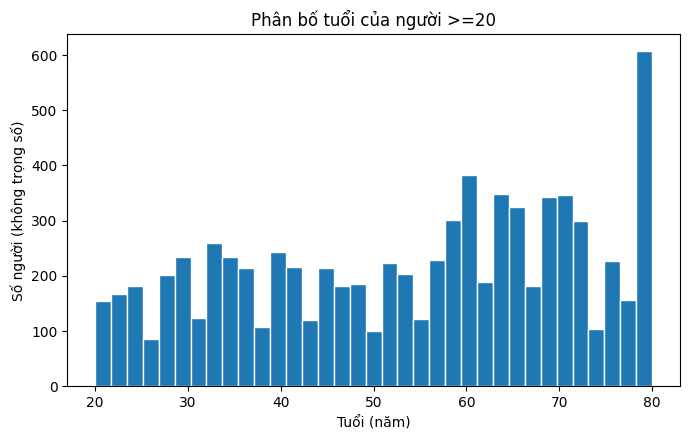

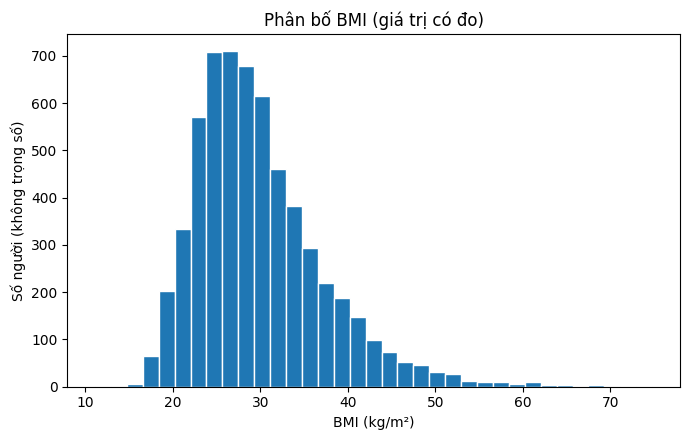

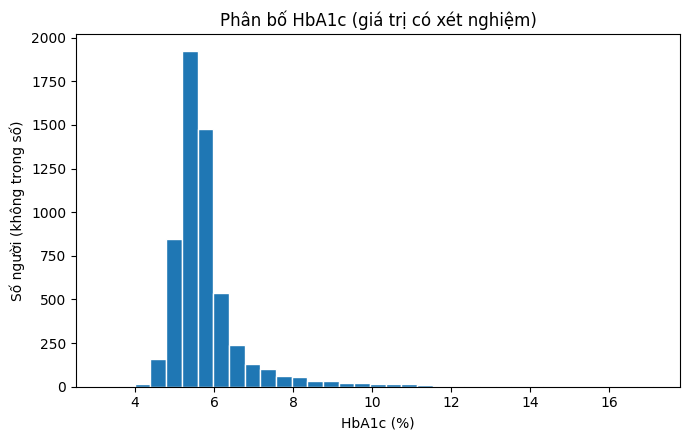

In [5]:
plots = [
    ("RIDAGEYR", "Phân bố tuổi của người >=20", "Tuổi (năm)", "eda_01_age.png"),
    ("BMXBMI", "Phân bố BMI (giá trị có đo)", "BMI (kg/m²)", "eda_02_bmi.png"),
    ("LBXGH", "Phân bố HbA1c (giá trị có xét nghiệm)", "HbA1c (%)", "eda_03_hba1c.png"),
]
for col, title, xlabel, filename in plots:
    values = adults[col].dropna()
    plt.figure(figsize=(7,4.5))
    plt.hist(values, bins=35, edgecolor="white")
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel("Số người (không trọng số)")
    finish_plot(filename)

## 6. Biểu đồ missingness và tỷ lệ có HbA1c theo độ tuổi

**Chú ý:** Tỷ lệ thiếu/được đo mang tính mô tả của dữ liệu đang xét. Không suy ra trực tiếp sự phổ biến bệnh trong quần thể.

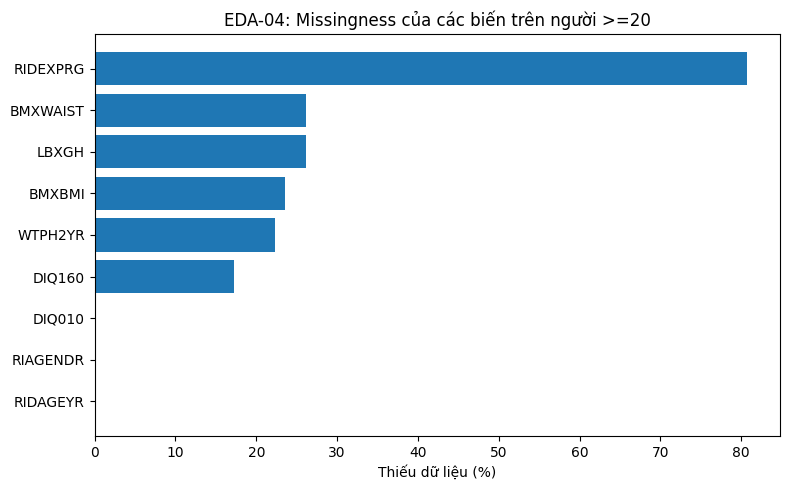

,n,measured,measured_pct
age_group,,,
20-29,904,601,66.48
30-39,1180,850,72.03
40-49,1042,775,74.38
50-59,1179,896,76.00
60-69,1765,1408,79.77
70-79,1214,916,75.45
80+,525,321,61.14


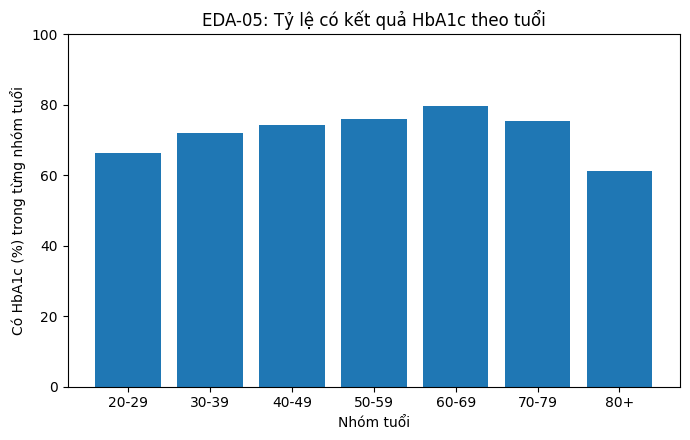

In [6]:
to_plot = missing.sort_values("missing_pct")
plt.figure(figsize=(8,5))
plt.barh(to_plot.index, to_plot["missing_pct"])
plt.xlabel("Thiếu dữ liệu (%)")
plt.title("EDA-04: Missingness của các biến trên người >=20")
finish_plot("eda_04_missingness.png")

age_coverage = adults.groupby("age_group", observed=False)["LBXGH"].agg(n="size", measured="count")
age_coverage["measured_pct"] = (100 * age_coverage["measured"] / age_coverage["n"]).round(2)
display(age_coverage)
plt.figure(figsize=(7,4.5))
plt.bar(age_coverage.index.astype(str), age_coverage["measured_pct"])
plt.ylim(0,100)
plt.ylabel("Có HbA1c (%) trong từng nhóm tuổi")
plt.xlabel("Nhóm tuổi")
plt.title("EDA-05: Tỷ lệ có kết quả HbA1c theo tuổi")
finish_plot("eda_05_hba1c_coverage_by_age.png")

## 7. Khảo sát BMI và HbA1c (không suy luận nhân quả)

Chỉ những dòng có đủ cả BMI và HbA1c mới được hiển thị. Hệ số tương quan Pearson nếu in ra là **mô tả trên mẫu có đo cả hai biến**, không chứng minh quan hệ nhân quả, không đo hiệu quả dự đoán.

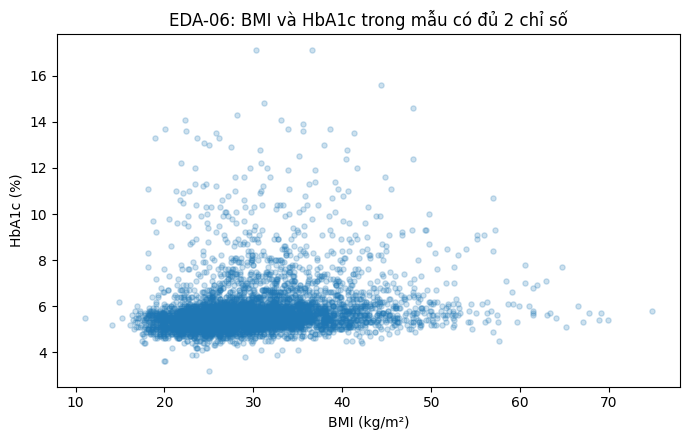

Pearson r (mô tả, không trọng số): 0.194


In [7]:
paired = adults[["BMXBMI", "LBXGH"]].dropna()
plt.figure(figsize=(7,4.5))
plt.scatter(paired["BMXBMI"], paired["LBXGH"], alpha=0.22, s=14)
plt.xlabel("BMI (kg/m²)")
plt.ylabel("HbA1c (%)")
plt.title("EDA-06: BMI và HbA1c trong mẫu có đủ 2 chỉ số")
finish_plot("eda_06_bmi_hba1c_scatter.png")
if len(paired) >= 3 and paired.nunique().min() > 1:
    print("Pearson r (mô tả, không trọng số):", round(float(paired["BMXBMI"].corr(paired["LBXGH"])), 3))
else:
    print("Chưa đủ dữ liệu để tính tương quan.")

## 8. Tần suất `DIQ010` và `DIQ160`

Theo codebook CDC: `DIQ010`: 1 = Yes, 2 = No, 3 = Borderline, 7 = Refused, 9 = Don't know. **Đây là câu trả lời đã từng được thông báo**, không phải nhãn bệnh đã được xét nghiệm xác nhận. `DIQ160` có skip logic; **NaN không có nghĩa 'No'**.

,n
DIQ010,
No,6466
Yes,1070
Borderline,270
Missing / other,2
Don't know,1


,n
DIQ160,
No,5579
Not asked / missing / other,1344
Yes,877
Don't know,9


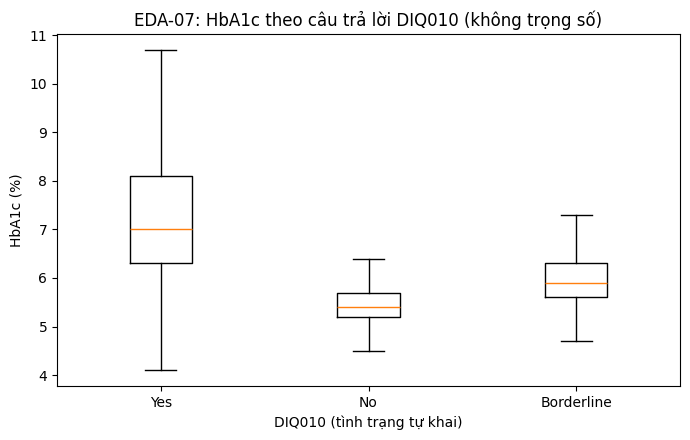

In [8]:
diq010_names = {1: "Yes", 2: "No", 3: "Borderline", 7: "Refused", 9: "Don't know"}
diQ = adults["DIQ010"].map(diq010_names).fillna("Missing / other")
display(diQ.value_counts(dropna=False).rename_axis("DIQ010").to_frame("n"))
if "DIQ160" in adults.columns:
    diq160_names = {1: "Yes", 2: "No", 7: "Refused", 9: "Don't know"}
    diq160 = adults["DIQ160"].map(diq160_names).fillna("Not asked / missing / other")
    display(diq160.value_counts(dropna=False).rename_axis("DIQ160").to_frame("n"))

by_code = adults.loc[adults["DIQ010"].isin([1,2,3]), ["DIQ010", "LBXGH"]].dropna()
groups = [by_code.loc[by_code["DIQ010"] == c, "LBXGH"].to_numpy() for c in [1,2,3]]
valid_groups = [(name, series) for name, series in zip(["Yes", "No", "Borderline"], groups) if len(series)]
if valid_groups:
    plt.figure(figsize=(7,4.5))
    plt.boxplot([series for _,series in valid_groups], showfliers=False)
    plt.xticks(range(1, len(valid_groups) + 1), [name for name, _ in valid_groups])
    plt.ylabel("HbA1c (%)")
    plt.xlabel("DIQ010 (tình trạng tự khai)")
    plt.title("EDA-07: HbA1c theo câu trả lời DIQ010 (không trọng số)")
    finish_plot("eda_07_hba1c_by_diq010.png")
else:
    print("Không có dữ liệu DIQ010 phù hợp để vẽ boxplot.")

## 9. Các khoảng HbA1c chỉ để mô tả (KHÔNG PHẢI NHÃN ML)

Có thể mô tả mẫu xét nghiệm theo các khoảng HbA1c: `<5.7`, `5.7–<6.5`, `>=6.5`. Đây **không phải** kết luận chẩn đoán hoặc nhãn mô hình đã được chốt. Không kết luận 'tiểu đường type 2' từ biểu đồ này.

In [9]:
observed = adults.loc[adults["LBXGH"].notna(), "LBXGH"]
a1c_ranges = pd.cut(
    observed, bins=[-np.inf,5.7,6.5,np.inf], right=False,
    labels=["<5.7%", "5.7%-<6.5%", ">=6.5%"]
)
ranges_table = a1c_ranges.value_counts(sort=False).to_frame("n")
ranges_table["pct_of_measured"] = (100 * ranges_table["n"] / len(observed)).round(2)
display(ranges_table)
print("CHỈ mô tả các khoảng xét nghiệm, chưa xác định nhãn hay bệnh.")

,n,pct_of_measured
LBXGH,,
<5.7%,3468,60.14
5.7%-<6.5%,1578,27.36
>=6.5%,721,12.50


CHỈ mô tả các khoảng xét nghiệm, chưa xác định nhãn hay bệnh.


## 10. Kết quả tổng hợp – **gửi lại cho người hướng dẫn**

Sao chép output dưới đây và gửi kèm ảnh những biểu đồ bạn nhận thấy có đặc điểm đáng chú ý. Người hướng dẫn sẽ cùng bạn ghi nhận vào `03-NHANES-EDA.md` và quyết định Bước 4 (preprocessing).

In [10]:
print("===== BƯỚC 3 — NHANES EDA (người dùng chạy) =====")
print("Python:", sys.version.split()[0], "| Pandas:", pd.__version__)
print("Merged:", merged.shape)
print("Adults >=20:", len(adults))
print("Adults có HbA1c:", int(has_hba1c.sum()))
print("Adults có BMI:", int(has_bmi.sum()))
print("Adults có đủ BMI + HbA1c:", n_paired)
print("HbA1c có nhưng BMI thiếu:", n_hba1c_no_bmi)
print("BMI có nhưng HbA1c thiếu:", n_bmi_no_hba1c)
for col in ["RIDAGEYR", "BMXBMI", "LBXGH"]:
    print(f"{col}: median={adults[col].median():.3f}; min={adults[col].min():.3f}; max={adults[col].max():.3f}")
print("Missing (%):")
print(missing["missing_pct"].round(2).to_string())
print("DIQ010 counts:")
print(diQ.value_counts().to_string())
print("Tỷ lệ có HbA1c theo nhóm tuổi (%):")
print(age_coverage["measured_pct"].to_string())
print("Đã có đủ các biểu đồ trong:", OUT_DIR)
print("===== KẾT THÚC — CHƯA TRAIN =====")

===== BƯỚC 3 — NHANES EDA (người dùng chạy) =====
Python: 3.13.9 | Pandas: 3.0.0
Merged: (11933, 13)
Adults >=20: 7809
Adults có HbA1c: 5767
Adults có BMI: 5970
Adults có đủ BMI + HbA1c: 5686
HbA1c có nhưng BMI thiếu: 81
BMI có nhưng HbA1c thiếu: 284
RIDAGEYR: median=57.000; min=20.000; max=80.000
BMXBMI: median=28.500; min=11.100; max=74.800
LBXGH: median=5.500; min=3.200; max=17.100
Missing (%):
RIDEXPRG    80.75
BMXWAIST    26.21
LBXGH       26.15
BMXBMI      23.55
WTPH2YR     22.35
DIQ160      17.21
DIQ010       0.03
RIDAGEYR     0.00
RIAGENDR     0.00
DIQ010 counts:
DIQ010
No                 6466
Yes                1070
Borderline          270
Missing / other       2
Don't know            1
Tỷ lệ có HbA1c theo nhóm tuổi (%):
age_group
20-29    66.48
30-39    72.03
40-49    74.38
50-59    76.00
60-69    79.77
70-79    75.45
80+      61.14
Đã có đủ các biểu đồ trong: C:\Users\ThinkPad\Multi-Agent_Du_doan_benh_tieu_duong\GĐ3\03-ML-Research\data\outputs\eda
===== KẾT THÚC — CHƯA TRAIN

## 11. Dừng ở đây trước khi sang Bước 4

- Không gọi `.fit()`, `.predict()`, không tạo `train_test_split` hay lưu mô hình trong notebook này.
- Không xóa các dòng có kết quả HbA1c thiếu để tính tỷ lệ dân số; chỉ dùng mẫu có xét nghiệm khi xem phân bố HbA1c.
- Không tự ý loại mẫu mang thai dựa trên `RIDEXPRG` thiếu.
- Khi đã chạy: gửi **output ô tổng hợp cuối** và biểu đồ **BMI**, **HbA1c**, **tỷ lệ missingness** (hoặc các biểu đồ bạn muốn phân tích).
- Tài liệu sẽ được cập nhật dựa trên output thực tế do bạn gửi.

### Nguồn CDC
- https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm
- https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DIQ_L.htm
- https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/GHB_L.htm
- https://wwwn.cdc.gov/nchs/nhanes/continuousnhanes/default.aspx?Cycle=2021-2023